In [1]:
import warnings
warnings.filterwarnings('ignore')

import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, accuracy_score, recall_score,
                             precision_score, f1_score, average_precision_score)
from xgboost import XGBClassifier

sns.set_style('whitegrid')
%matplotlib inline

In [2]:
TARGET = 'PCOS (Y/N)'
SEED = 42

IMPOSSIBLE = {
    'Pulse rate(bpm)': (40, 200),
    'BP _Systolic (mmHg)': (70, 250),
    'BP _Diastolic (mmHg)': (40, 150),
    'FSH(mIU/mL)': (0, 100),
    'LH(mIU/mL)': (0, 100),
    'Vit D3 (ng/mL)': (0, 200),
}

train_real = pd.read_csv('run_final/train_real.csv')
test_real  = pd.read_csv('run_final/test_real.csv')
aug_train  = pd.read_csv('run_final/augmented_train.csv')
for d in (train_real, test_real, aug_train):
    d.columns = d.columns.str.strip()

# leak guards (raw values, before any cleaning)
rk = lambda d: set(d[list(train_real.columns)].round(4).astype(str).agg('|'.join, axis=1))
assert not (rk(test_real) & rk(train_real)), 'train/test overlap'
assert not (rk(test_real) & rk(aug_train)), 'TEST ROW INSIDE AUGMENTED TRAIN'
for d in (train_real, test_real, aug_train):
    assert set(d['Cycle(R/I)'].unique()) <= {0, 1}, 'cycle not 0/1'
print('leak guards passed')
print('train_real', train_real.shape, '| test_real', test_real.shape, '| aug_train', aug_train.shape)

leak guards passed
train_real (432, 42) | test_real (109, 42) | aug_train (1932, 42)


In [3]:
print('duplicates (real train):', train_real.duplicated().sum())
print('nulls (real train):', int(train_real.isnull().sum().sum()))

bad = {c: int(((train_real[c] < lo) | (train_real[c] > hi)).sum()) for c, (lo, hi) in IMPOSSIBLE.items()}
print('impossible values in real train:', bad)

def clean(d):
    d = d.copy()
    for c, (lo, hi) in IMPOSSIBLE.items():
        d.loc[(d[c] < lo) | (d[c] > hi), c] = np.nan
    d['BMI'] = d['Weight (Kg)'] / (d['Height(Cm)'] / 100) ** 2
    d['Waist:Hip Ratio'] = d['Waist(inch)'] / d['Hip(inch)']
    d['FSH/LH'] = (d['FSH(mIU/mL)'] / d['LH(mIU/mL)']).replace([np.inf, -np.inf], np.nan)
    return d

train_real, test_real, aug_train = clean(train_real), clean(test_real), clean(aug_train)
df = train_real.copy()      # EDA cells (2-10) use real train only

df.isnull().sum()[df.isnull().sum() > 0]

duplicates (real train): 0
nulls (real train): 0
impossible values in real train: {'Pulse rate(bpm)': 2, 'BP _Systolic (mmHg)': 1, 'BP _Diastolic (mmHg)': 1, 'FSH(mIU/mL)': 1, 'LH(mIU/mL)': 0, 'Vit D3 (ng/mL)': 2}


Pulse rate(bpm)         2
FSH(mIU/mL)             1
FSH/LH                  1
Vit D3 (ng/mL)          2
BP _Systolic (mmHg)     1
BP _Diastolic (mmHg)    1
dtype: int64

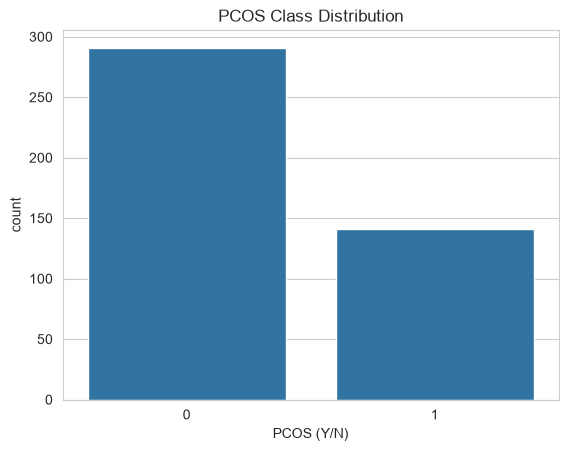

PCOS (Y/N)
0    0.673611
1    0.326389
Name: proportion, dtype: float64

In [4]:
sns.countplot(x=TARGET, data=df)
plt.title('PCOS Class Distribution')
plt.show()
df[TARGET].value_counts(normalize=True)

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PCOS (Y/N),432.0,0.326389,0.469435,0.000000,0.000000,0.000000,1.000000,1.000000
Age (yrs),432.0,31.416667,5.434059,20.000000,27.000000,31.000000,35.000000,48.000000
Weight (Kg),432.0,59.414120,11.173571,31.000000,52.000000,59.000000,65.000000,108.000000
Height(Cm),432.0,156.376324,6.074958,137.000000,152.000000,156.000000,160.000000,180.000000
BMI,432.0,24.259835,4.093020,12.417882,21.614498,24.127541,26.666667,38.900714
Blood Group,432.0,13.798611,1.861491,11.000000,13.000000,14.000000,15.000000,18.000000
Pulse rate(bpm),430.0,73.453488,2.654358,70.000000,72.000000,72.000000,74.000000,82.000000
RR (breaths/min),432.0,19.256944,1.708773,16.000000,18.000000,18.000000,20.000000,28.000000
Hb(g/dl),432.0,11.172407,0.872668,9.000000,10.500000,11.000000,11.725000,14.800000
Cycle(R/I),432.0,0.287037,0.452904,0.000000,0.000000,0.000000,1.000000,1.000000


In [6]:
corr = df.corr(numeric_only=True)[TARGET].sort_values(ascending=False)
corr

PCOS (Y/N)                1.000000
Follicle No. (R)          0.649424
Follicle No. (L)          0.617717
Skin darkening (Y/N)      0.476877
hair growth(Y/N)          0.458256
Weight gain(Y/N)          0.457088
Cycle(R/I)                0.376799
Fast food (Y/N)           0.364475
AMH(ng/mL)                0.292630
Pimples(Y/N)              0.284462
Weight (Kg)               0.233161
Waist(inch)               0.214777
BMI                       0.214322
Hip(inch)                 0.200050
Hair loss(Y/N)            0.188680
Avg. F size (L) (mm)      0.160746
Endometrium (mm)          0.126799
Avg. F size (R) (mm)      0.125671
Pulse rate(bpm)           0.104743
LH(mIU/mL)                0.100054
Height(Cm)                0.089204
Hb(g/dl)                  0.085411
Reg.Exercise(Y/N)         0.065940
FSH/LH                    0.061945
RBS(mg/dl)                0.046985
II    beta-HCG(mIU/mL)    0.037121
Waist:Hip Ratio           0.035617
Blood Group               0.035568
RR (breaths/min)    

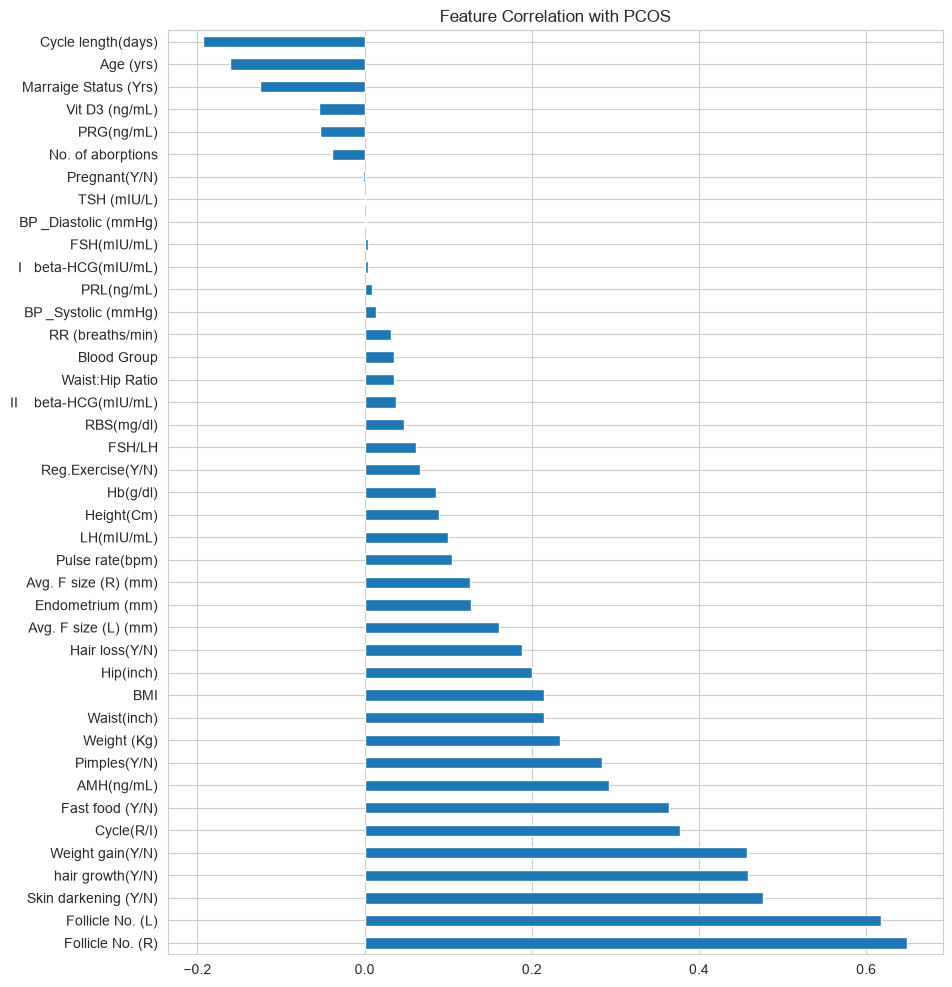

In [7]:
plt.figure(figsize=(10, 12))
corr.drop(TARGET).plot(kind='barh')
plt.title('Feature Correlation with PCOS')
plt.show()

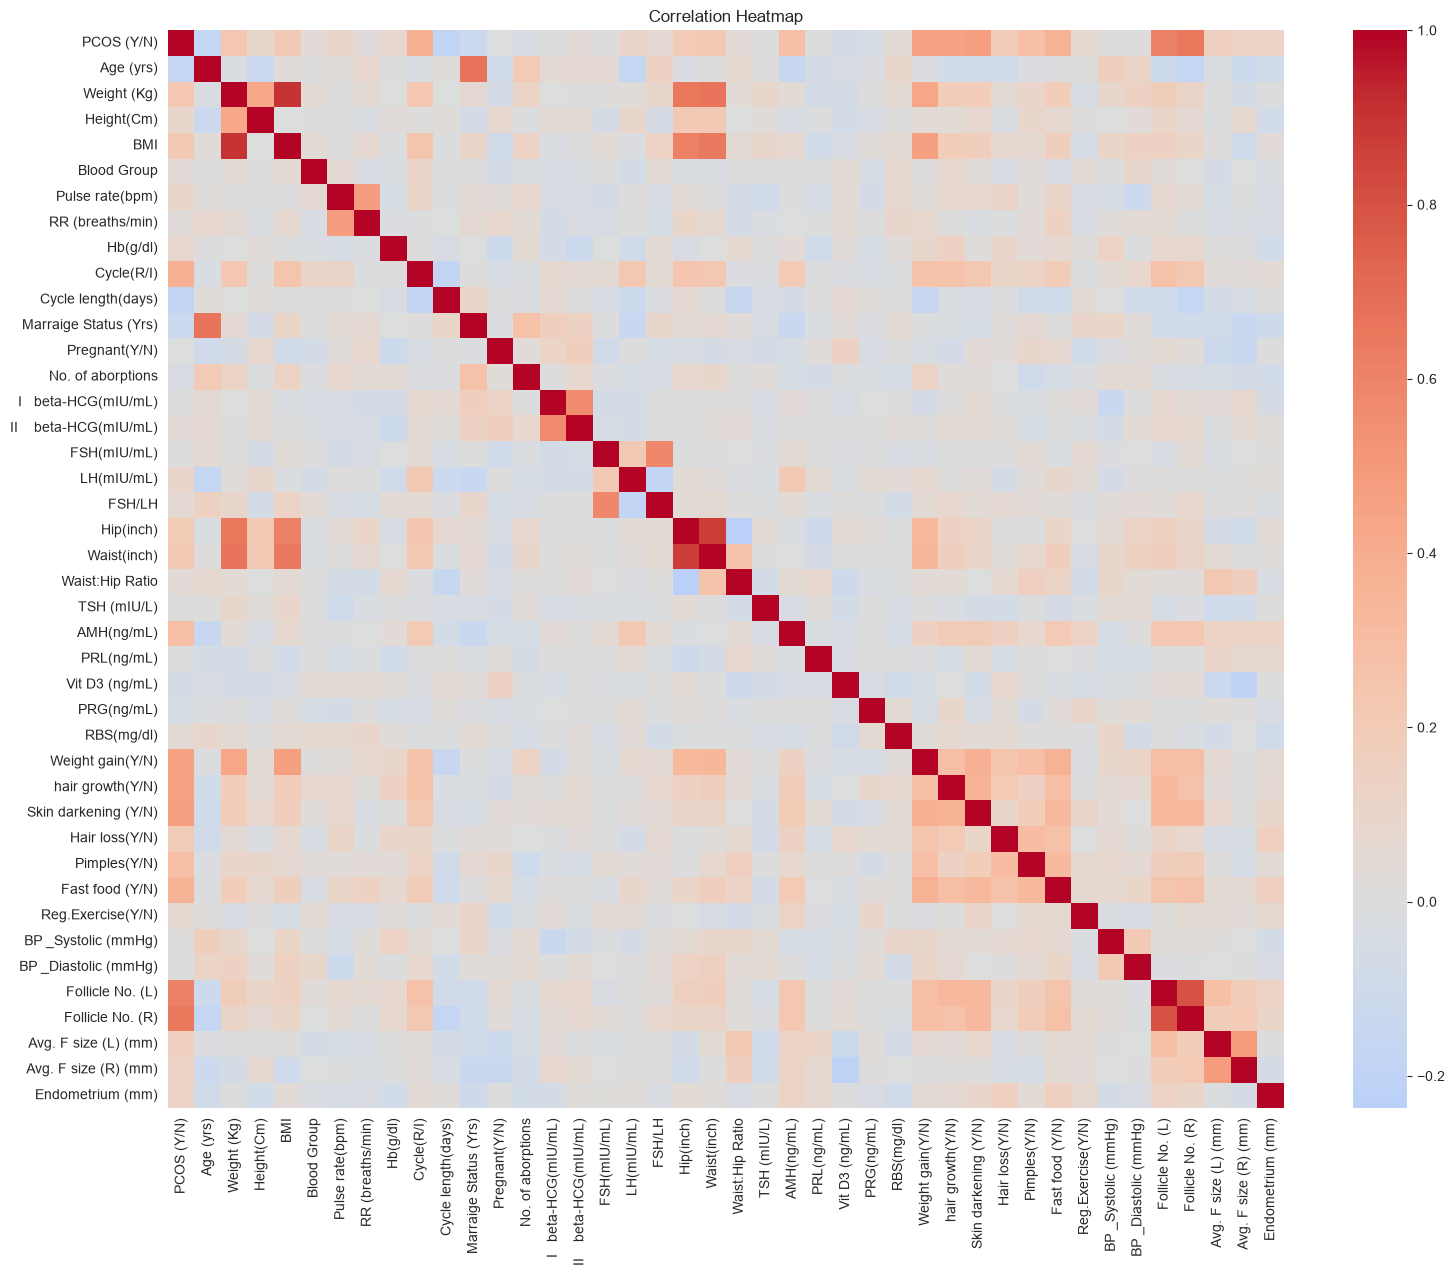

In [8]:
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

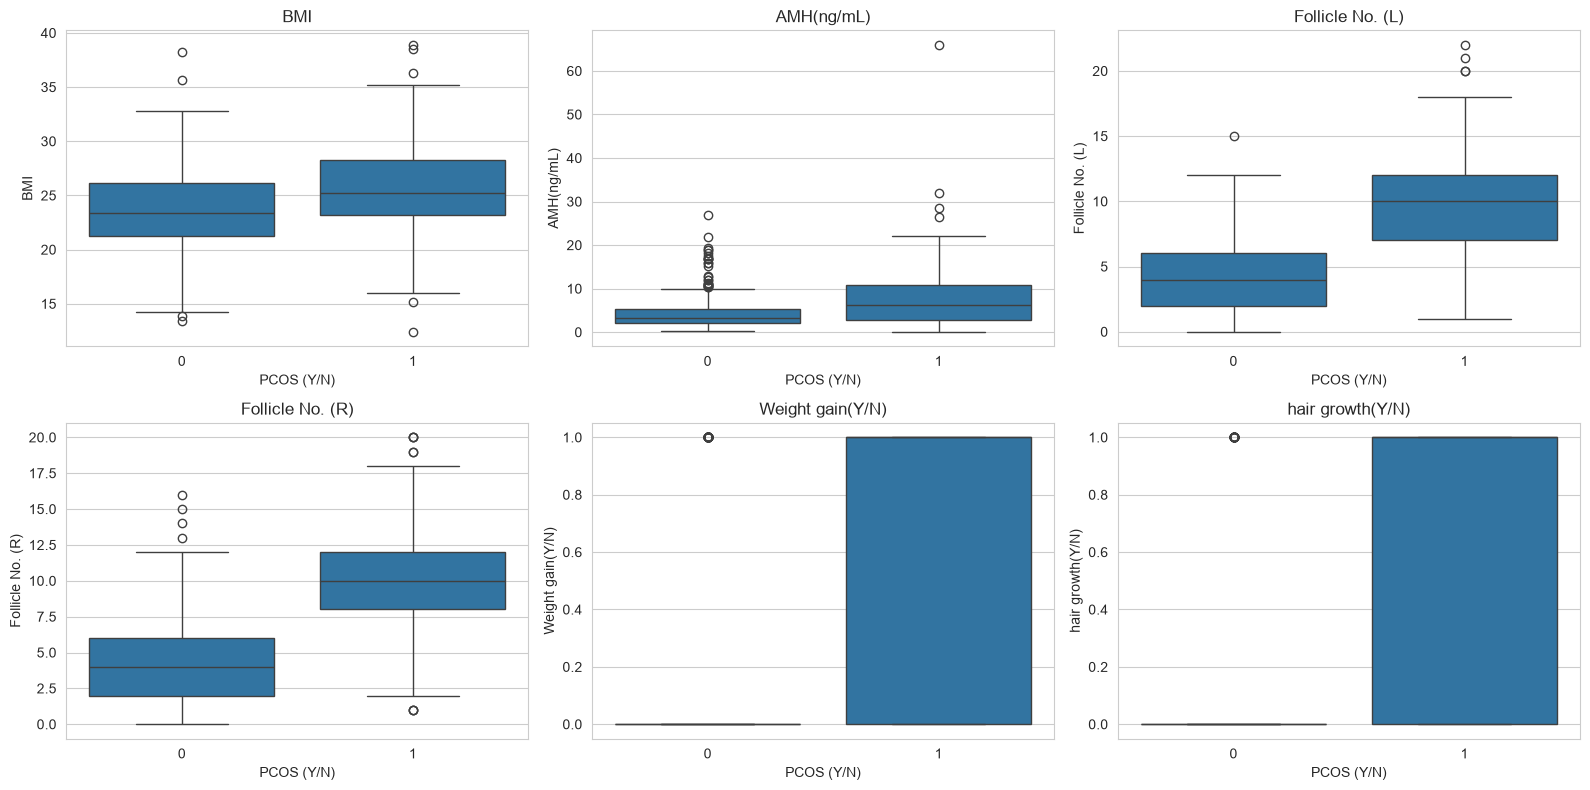

In [9]:
key_features = ['BMI', 'AMH(ng/mL)', 'Follicle No. (L)', 'Follicle No. (R)', 'Weight gain(Y/N)', 'hair growth(Y/N)']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feat in zip(axes.flatten(), key_features):
    sns.boxplot(x=TARGET, y=feat, data=df, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

In [10]:
cols = [c for c in train_real.columns if c != TARGET]
X_train, y_train = train_real[cols], train_real[TARGET]     
X_test,  y_test  = test_real[cols],  test_real[TARGET]      
train_sets = {'Real only': train_real, 'Real + synthetic': aug_train}

for k, v in train_sets.items():
    print(f'{k:18s}', v.shape, 'pos rate %.3f' % v[TARGET].mean())
print('test (all real):  ', X_test.shape, 'pos rate %.3f' % y_test.mean())

Real only          (432, 42) pos rate 0.326
Real + synthetic   (1932, 42) pos rate 0.327
test (all real):   (109, 41) pos rate 0.330


In [11]:
def make_pipes(y):
    pos_w = (y == 0).sum() / (y == 1).sum()
    models = {
        'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', C=0.5),
        'Random Forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                            class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                            colsample_bytree=0.8, scale_pos_weight=pos_w, eval_metric='logloss',
                            random_state=SEED, n_jobs=-1),
        'SVM': SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=SEED),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                            max_depth=3, subsample=0.8, random_state=SEED),
    }
    needs_scaling = ['Logistic Regression', 'SVM']
    pipes = {}
    for name, m in models.items():
        steps = [('imputer', SimpleImputer(strategy='median'))]
        if name in needs_scaling:
            steps.append(('scaler', StandardScaler()))
        steps.append(('model', m))
        pipes[name] = Pipeline(steps)
    return pipes

pipes = make_pipes(y_train)     # real-only pipes, used by Cell 13 CV
list(pipes)

['Logistic Regression', 'Random Forest', 'XGBoost', 'SVM', 'Gradient Boosting']

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'accuracy': 'accuracy'}

rows = []
for name, p in pipes.items():
    r = cross_validate(p, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'model': name, **{k: r['test_' + k].mean() for k in scoring},
                 'auc_std': r['test_auc'].std()})

cv_table = pd.DataFrame(rows).set_index('model').sort_values('auc', ascending=False)
best_name = cv_table.index[0]
print('Best model by CV AUC:', best_name)
cv_table.round(3)

Best model by CV AUC: Random Forest


,auc,recall,precision,f1,accuracy,auc_std
model,,,,,,
Random Forest,0.955,0.802,0.902,0.847,0.905,0.019
Gradient Boosting,0.948,0.802,0.866,0.830,0.891,0.022
XGBoost,0.945,0.823,0.818,0.819,0.880,0.021
Logistic Regression,0.936,0.844,0.766,0.803,0.864,0.014
SVM,0.930,0.809,0.759,0.782,0.852,0.016


In [13]:
fitted, probs, rows = {}, {}, []
for set_name, tr in train_sets.items():
    Xtr, ytr = tr[cols], tr[TARGET]
    for name, p in make_pipes(ytr).items():
        p.fit(Xtr, ytr)
        pr = p.predict_proba(X_test)[:, 1]
        pred = (pr >= 0.5).astype(int)
        fitted[(set_name, name)] = p
        probs[(set_name, name)] = pr
        rows.append({'train set': set_name, 'model': name,
                     'auc': roc_auc_score(y_test, pr),
                     'pr_auc': average_precision_score(y_test, pr),
                     'accuracy': accuracy_score(y_test, pred),
                     'recall': recall_score(y_test, pred),
                     'precision': precision_score(y_test, pred, zero_division=0),
                     'f1': f1_score(y_test, pred)})

test_table = pd.DataFrame(rows).set_index(['train set', 'model'])
test_table.round(3)

auc  pr_auc  accuracy  recall  \
train set        model                                                  
Real only        Logistic Regression  0.939   0.924     0.872   0.861   
                 Random Forest        0.932   0.929     0.936   0.833   
                 XGBoost              0.950   0.940     0.908   0.833   
                 SVM                  0.936   0.920     0.908   0.833   
                 Gradient Boosting    0.947   0.938     0.917   0.806   
Real + synthetic Logistic Regression  0.946   0.913     0.899   0.944   
                 Random Forest        0.943   0.907     0.881   0.833   
                 XGBoost              0.937   0.910     0.890   0.889   
                 SVM                  0.925   0.881     0.881   0.722   
                 Gradient Boosting    0.941   0.918     0.908   0.861   

                                      precision     f1  
train set        model                                  
Real only        Logistic Regression      0.775  0.816  
                 Random Forest            0.968  0.896  
                 XGBoost                  0.882  0.857  
                 SVM                      0.882  0.857  
                 Gradient Boosting        0.935  0.866  
Real + synthetic Logistic Regression      0.791  0.861  
                 Random Forest            0.811  0.822  
                 XGBoost                  0.800  0.842  
                 SVM                      0.897  0.800  
                 Gradient Boosting        0.861  0.861

In [14]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
p_real = probs[('Real only', best_name)]
p_aug = probs[('Real + synthetic', best_name)]
diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) == 2:
        diffs.append(roc_auc_score(yt[idx], p_aug[idx]) - roc_auc_score(yt[idx], p_real[idx]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print('AUC gain (aug - real) 95%% CI: %.3f to %.3f' % (lo, hi))
print('CI includes 0 -> no proven benefit' if lo <= 0 <= hi else 'CI excludes 0 -> real benefit')

AUC gain (aug - real) 95% CI: -0.018 to 0.045
CI includes 0 -> no proven benefit


In [15]:
auc_by_set = {s: roc_auc_score(y_test, probs[(s, best_name)]) for s in train_sets}
print('Test AUC of', best_name, ':', {k: round(v, 4) for k, v in auc_by_set.items()})

# synthetic must earn its place: >= 0.01 AUC gain, else keep simpler real-only model
chosen_set = 'Real only'   # synthetic gave no reliable gain (paired bootstrap CI includes 0)
print('Selected by real-only CV:', best_name, '| train set:', chosen_set)

best = fitted[(chosen_set, best_name)]
probs_chosen = {n: probs[(chosen_set, n)] for n in pipes}
pr_best = probs_chosen[best_name]
print(classification_report(y_test, (pr_best >= 0.5).astype(int), target_names=['No PCOS', 'PCOS']))

rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
aucs = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) == 2:
        aucs.append(roc_auc_score(yt[idx], pr_best[idx]))
print('Test AUC 95%% CI for %s: %.3f - %.3f' % (best_name, np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)))

Test AUC of Random Forest : {'Real only': 0.9319, 'Real + synthetic': 0.9429}
Selected by real-only CV: Random Forest | train set: Real only
              precision    recall  f1-score   support

     No PCOS       0.92      0.99      0.95        73
        PCOS       0.97      0.83      0.90        36

    accuracy                           0.94       109
   macro avg       0.95      0.91      0.92       109
weighted avg       0.94      0.94      0.93       109

Test AUC 95% CI for Random Forest: 0.860 - 0.989


In [16]:
side = test_table.reset_index().pivot(index='model', columns='train set', values=['auc', 'recall', 'f1'])
side[('auc', 'gain (aug - real)')] = side[('auc', 'Real + synthetic')] - side[('auc', 'Real only')]
side.round(3)

auc                     recall            \
train set           Real + synthetic Real only Real + synthetic Real only   
model                                                                       
Gradient Boosting              0.941     0.947            0.861     0.806   
Logistic Regression            0.946     0.939            0.944     0.861   
Random Forest                  0.943     0.932            0.833     0.833   
SVM                            0.925     0.936            0.722     0.833   
XGBoost                        0.937     0.950            0.889     0.833   

                                  f1                         auc  
train set           Real + synthetic Real only gain (aug - real)  
model                                                             
Gradient Boosting              0.861     0.866            -0.006  
Logistic Regression            0.861     0.816             0.007  
Random Forest                  0.822     0.896             0.011  
SVM                            0.800     0.857            -0.010  
XGBoost                        0.842     0.857            -0.013

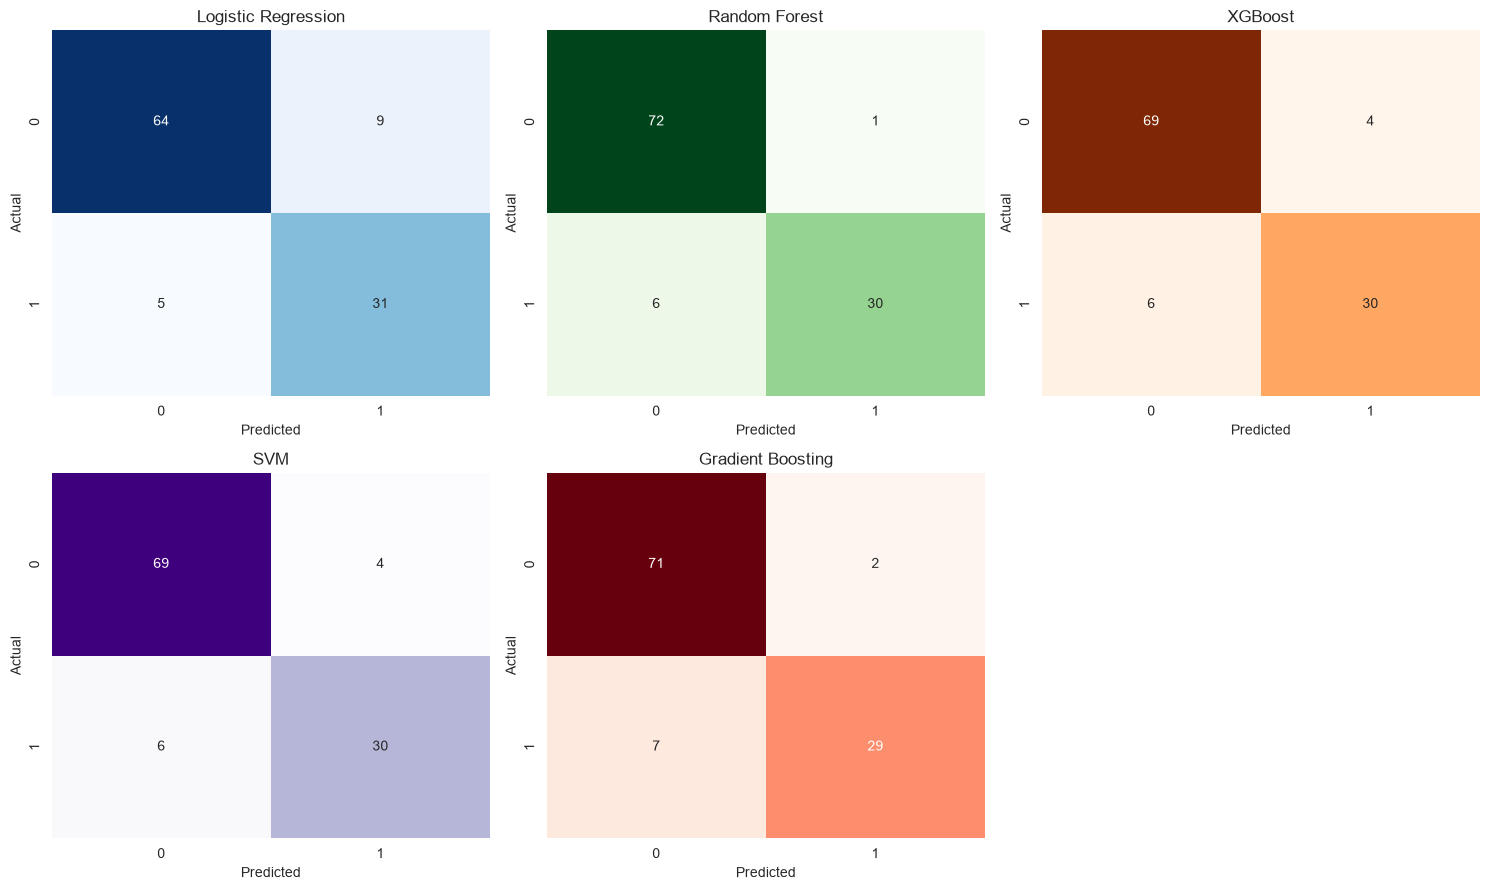

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
cmaps = ['Blues', 'Greens', 'Oranges', 'Purples', 'Reds']
for ax, (name, pr), cm in zip(axes.flatten(), probs_chosen.items(), cmaps):
    sns.heatmap(confusion_matrix(y_test, (pr >= 0.5).astype(int)), annot=True, fmt='d', cmap=cm, ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
axes[1, 2].axis('off')
plt.tight_layout(); plt.show()

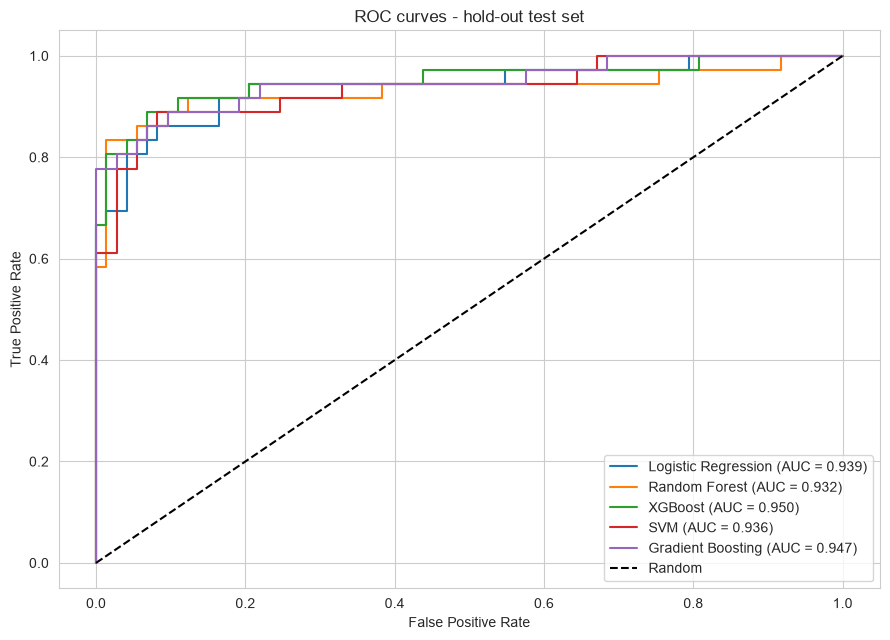

In [18]:
plt.figure(figsize=(9, 6.5))
for name, pr in probs_chosen.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, pr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC curves - hold-out test set'); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

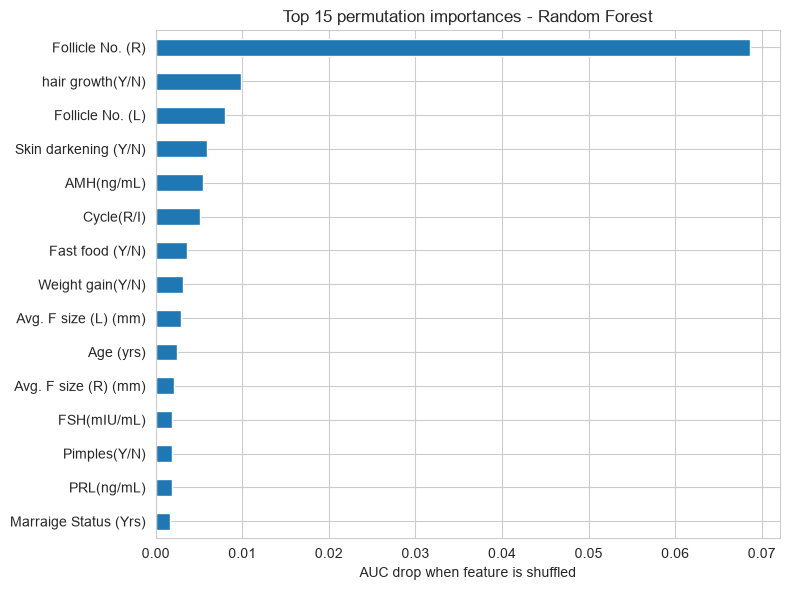

In [19]:
perm = permutation_importance(best, X_test, y_test, scoring='roc_auc',
                              n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=cols).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot(kind='barh', figsize=(8, 6))
plt.title(f'Top 15 permutation importances - {best_name}')
plt.xlabel('AUC drop when feature is shuffled'); plt.tight_layout(); plt.show()

In [20]:
import os
os.makedirs('../models', exist_ok=True)

feature_medians = {c: float(X_train[c].median()) for c in cols}     # real train only
assert feature_medians['Cycle(R/I)'] in (0.0, 1.0), 'cycle median wrong'
assert set(train_sets[chosen_set]['Cycle(R/I)'].unique()) <= {0, 1}

with open('../models/feature_medians.json', 'w') as f:
    json.dump(feature_medians, f, indent=2)
with open('../models/feature_schema.pkl', 'wb') as f:
    pickle.dump(cols, f)

tr = train_sets[chosen_set]
final_rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                  class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)
final_rf.fit(tr[cols].fillna(feature_medians), tr[TARGET])

with open('../models/rf_pcos_model.pkl', 'wb') as f:
    pickle.dump(final_rf, f)

with open('../models/feature_schema.pkl', 'rb') as f:
    schema_check = pickle.load(f)
with open('../models/feature_medians.json') as f:
    medians_check = json.load(f)
with open('../models/rf_pcos_model.pkl', 'rb') as f:
    model_check = pickle.load(f)

assert schema_check == cols
assert list(medians_check) == cols
assert list(model_check.feature_names_in_) == cols

reloaded_prob = model_check.predict_proba(X_test[schema_check].fillna(medians_check))[:, 1]
print('saved in      :', os.path.abspath('../models'))
print('trained on    :', chosen_set, tr.shape)
print('Cycle median  :', medians_check['Cycle(R/I)'])
print('features      :', len(schema_check))
print('reloaded RF test AUC: %.3f' % reloaded_prob.mean() if False else 'reloaded RF test AUC: %.3f' % roc_auc_score(y_test, reloaded_prob))

saved in      : c:\Users\MARUTIRAJ\Desktop\CycleTwin_AI-1\models
trained on    : Real only (432, 42)
Cycle median  : 0.0
features      : 41
reloaded RF test AUC: 0.932
